# Fed-PIEdgeGT v2 — Updated Colab Research Pipeline

Source-holdout cyberattack detection with tuned tree baselines, a smaller graph model with a direct tabular branch, and source-based federated experiments.

**Run the smoke profile first. Pilot is the default; full mode runs five outer folds, four inner folds and three seeds. Performance gains are not guaranteed. Physics residuals stay disabled until authoritative channel metadata are verified.**

All 15 CSV files are required. This notebook contains the complete implementation. It does not require the companion `.py` file. Select a GPU runtime for the neural/FL experiments. Keep results in Drive so completed folds survive a Colab disconnect.

## 1. Environment setup
Install missing packages. Preserve Colab's existing PyTorch GPU build. The tested CPU environment is recorded in the accompanying validation file; each run exports an exact environment lock.

In [1]:
import sys, subprocess, importlib.util, os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
requirements = {
    "numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<3",
    "scipy": "scipy>=1.12,<2", "sklearn": "scikit-learn>=1.4,<2",
    "joblib": "joblib>=1.3,<2", "matplotlib": "matplotlib>=3.8,<4",
    "torch": "torch>=2.5,<3", "xgboost": "xgboost>=3.0,<4",
}
missing = [spec for module, spec in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Dependencies available. Restart the runtime if an install asks you to.")

Dependencies available. Restart the runtime if an install asks you to.


## 2. Optional Google Drive mount
Set `MOUNT_DRIVE=True` when the datasets and output folder are in Drive. Otherwise upload the CSVs to `/content` using Colab's Files panel.

In [15]:
MOUNT_DRIVE = True
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## 3. Implementation
Definitions below do not start experiments. Every inner split fits its own training-only preprocessing. The outer test labels are used for reporting only. Do not modify candidates after inspecting their outer-test results.

In [3]:
PIPELINE_CODE_SHA256 = "f1f5d1097614c5446cf89cb420e4f76374dc3073950b6892ddb91d96efd7a6dc"

### Imports and reproducibility

In [4]:
"""Fed-PIEdgeGT v2: source-holdout power-system cyberattack detection.
Self-contained CPU/GPU experiment runner. No temporal or formal privacy claim.
Run --help for profiles. Dataset: data1.csv ... data15.csv; label marker.
"""
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import argparse, copy, hashlib, importlib.metadata, json, math, platform, random, time
from pathlib import Path
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
    brier_score_loss, log_loss, precision_recall_fscore_support)
import joblib
try:
    import torch
    from torch import nn
    from torch.nn import functional as F
except ImportError:
    torch = None

@dataclass
class Config:
    data_dir: str = '/content'
    output_dir: str = '/content/Fed_PIEdgeGT_v2_results'
    profile: str = 'pilot'
    outer_folds: int = 5
    inner_folds: int = 3
    folds: tuple = (0,)
    seeds: tuple = (11,)
    epochs: int = 30
    patience: int = 8
    batch_size: int = 512
    fl_rounds: int = 40
    local_steps: int = 20
    n_clients: int = 4
    partitions: tuple = ('source',)
    fl_algorithms: tuple = ('FedAvg', 'FedProx', 'FedAdam', 'SCAFFOLD')
    families: tuple = ('HistGB_raw', 'HistGB_nolog', 'XGBoost_raw', 'XGBoost_nolog', 'ExtraTrees', 'MLP', 'EdgeGT')
    fl_backbone: str = 'EdgeGT'
    physics_verified: bool = False
    physics_reference: str = ''
    angle_unit: str = 'degrees'
    v_sequence: tuple = (7, 8, 9)  # positive, negative, zero; gated pending verification
    i_sequence: tuple = (10, 11, 12)
    edges: tuple = ((0, 1), (2, 3))  # inherited topology hypothesis; not certified
    topology_reference: str = 'Unverified topology hypothesis inherited from supplied notebook'
    clip: float = 8.0
    seed: int = 42
    max_rows_per_source: int = 0
    bootstrap: int = 2000
    run_fl: bool = True
    trees_only: bool = False
    resume: bool = False
    run_random_reference: bool = False

    @classmethod
    def make(cls, profile='pilot', **kwargs):
        c = cls(profile=profile)
        if profile == 'smoke':
            c.inner_folds = 2; c.epochs = 2; c.patience = 2
            c.fl_rounds = 2; c.local_steps = 2; c.batch_size = 128
            c.max_rows_per_source = 80; c.bootstrap = 100
        elif profile == 'full':
            c.inner_folds = 4; c.folds = tuple(range(5)); c.seeds = (11, 29, 47)
            c.epochs = 100; c.patience = 15; c.fl_rounds = 120; c.local_steps = 30
            c.partitions = ('source', 'iid', 'dirichlet'); c.bootstrap = 5000
        elif profile != 'pilot':
            raise ValueError('profile must be smoke, pilot or full')
        for k, v in kwargs.items():
            if v is not None: setattr(c, k, v)
        return c


def seed_all(seed):
    random.seed(seed); np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True)


def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=lambda x:
        x.item() if isinstance(x, np.generic) else str(x)))


def code_hash():
    if '__file__' in globals(): return hashlib.sha256(Path(__file__).read_bytes()).hexdigest()
    return globals().get('PIPELINE_CODE_SHA256','unavailable')


def sync():
    if torch is not None and torch.cuda.is_available(): torch.cuda.synchronize()

### Dataset integrity and fixed source partitions

In [5]:

def load_data(cfg):
    frames, inventory, hashes = [], [], {}
    expected = None
    for i in range(1, 16):
        p = Path(cfg.data_dir) / f'data{i}.csv'
        if not p.is_file(): raise FileNotFoundError(f'Missing required dataset: {p}')
        hashes[p.name] = hashlib.sha256(p.read_bytes()).hexdigest()
        d = pd.read_csv(p)
        if expected is None: expected = list(d.columns)
        if list(d.columns) != expected: raise ValueError(f'Schema mismatch: {p.name}')
        if 'marker' not in d: raise ValueError('Expected target column marker')
        if d.shape[1] != 129: raise ValueError(f'{p.name}: expected 128 inputs + target')
        labels = d.marker.astype(str).str.strip()
        if set(labels) != {'Attack', 'Natural'}: raise ValueError(f'Unexpected classes: {p.name}')
        x = d.drop(columns='marker').apply(pd.to_numeric, errors='raise')
        inventory.append(dict(source=p.name, rows=len(d), attacks=int((labels=='Attack').sum()),
            nonattacks=int((labels=='Natural').sum()), missing=int(x.isna().sum().sum()),
            infinities=int(np.isinf(x.to_numpy()).sum()), duplicates=int(d.duplicated().sum())))
        d['marker'] = labels; d['_source'] = p.name; d['_row'] = np.arange(len(d))
        if cfg.max_rows_per_source:
            # Diagnostic subsampling only; class proportions approximately retained.
            d = d.groupby('marker', group_keys=False).sample(frac=min(1, cfg.max_rows_per_source/len(d)),
                                                            random_state=cfg.seed)
        frames.append(d)
    raw = pd.concat(frames, ignore_index=True)
    feat = raw[expected[:-1]] if expected[-1] == 'marker' else raw[[c for c in expected if c != 'marker']]
    feat = feat.replace([np.inf, -np.inf], np.nan)
    # Identical predictors cannot appear on both sides of a split. Remove ALL members
    # of cross-source duplicate clusters rather than arbitrarily assigning them.
    h = pd.util.hash_pandas_object(feat, index=False)
    collisions = pd.DataFrame({'hash':h, 'source':raw['_source']}).groupby('hash').source.nunique()
    bad = set(collisions[collisions > 1].index)
    cross = h.isin(bad).to_numpy()
    keep = ~cross & ~feat.duplicated(keep='first').to_numpy()
    duplicate_report = {'original_loaded_rows':len(raw), 'cross_source_duplicate_rows_removed':int(cross.sum()),
                        'within_source_duplicate_rows_removed':int((~cross & ~keep).sum()),
                        'retained_rows':int(keep.sum())}
    # Conflicting identical features are never resolved with majority-vote labels.
    conflicts = pd.DataFrame({'hash':h, 'label':raw.marker}).groupby('hash').label.nunique()
    conflict = h.isin(set(conflicts[conflicts>1].index)).to_numpy()
    duplicate_report['conflicting_feature_rows_removed'] = int((conflict & keep).sum())
    keep &= ~conflict
    duplicate_report['retained_rows'] = int(keep.sum())
    raw = raw.loc[keep].reset_index(drop=True)
    return raw, pd.DataFrame(inventory), hashes, duplicate_report


def assert_source_split(raw, train, val):
    assert not set(raw._source.iloc[train]) & set(raw._source.iloc[val]), 'Source leakage'
    assert not set(train) & set(val), 'Row leakage'
    y = (raw.marker == 'Attack').to_numpy(int)
    assert len(np.unique(y[train])) == 2 and len(np.unique(y[val])) == 2


def group_splits(raw, indices, k, seed):
    y = (raw.marker == 'Attack').to_numpy(int); g = raw._source.to_numpy()
    if len(np.unique(g[indices])) < k: raise ValueError('Not enough source groups')
    cv = StratifiedGroupKFold(k, shuffle=True, random_state=seed)
    out = []
    for a, b in cv.split(np.zeros(len(indices)), y[indices], g[indices]):
        tr, va = indices[a], indices[b]; assert_source_split(raw, tr, va); out.append((tr, va))
    return out

### Shared feature definitions; physics requires explicit metadata confirmation

In [6]:

def pm_cols(r, k):
    voltage = k in (1, 2, 3, 7, 8, 9)
    return (f'R{r}-PM{k}:{"V" if voltage else "I"}',
            f'R{r}-PA{k}:{"VH" if voltage else "IH"}')


def relay_columns(r):
    cols = []
    for k in range(1, 13):
        mag, ang = pm_cols(r, k); cols += [ang, mag]
    cols += [f'R{r}:F', f'R{r}:DF', f'R{r}-PA:Z', f'R{r}-PA:ZH', f'R{r}:S',
             f'control_panel_log{r}', f'relay{r}_log', f'snort_log{r}']
    return cols


def fortescue(a, b, c):
    rot = np.exp(2j*np.pi/3)
    return ((a+rot*b+rot**2*c)/3, (a+rot**2*b+rot*c)/3, (a+b+c)/3)


def feature_arrays(raw, cfg, no_logs=False, physics=False):
    if physics and (not cfg.physics_verified or not cfg.physics_reference.strip()):
        raise ValueError('Physics requires verified ABC order, angle units, sequence mapping, and reference')
    if physics:
        if cfg.angle_unit not in ('degrees','radians'): raise ValueError('Invalid angle_unit')
        if set(cfg.v_sequence)!={7,8,9} or set(cfg.i_sequence)!={10,11,12}:
            raise ValueError('Sequence mappings must each be permutations of their three channels')
    nodes, targets, valid = [], [], []
    for r in range(1, 5):
        cols = relay_columns(r)[:29] if no_logs else relay_columns(r)
        n = raw[cols].apply(pd.to_numeric, errors='raise').to_numpy(float)
        n[~np.isfinite(n)] = np.nan
        if physics:
            def z(k):
                mag, ang = pm_cols(r, k)
                m = raw[mag].to_numpy(float); a = raw[ang].to_numpy(float)
                a = np.deg2rad(a) if cfg.angle_unit == 'degrees' else a
                with np.errstate(invalid='ignore'): return m*np.exp(1j*a)
            vc = fortescue(*(z(k) for k in (1,2,3)))
            ic = fortescue(*(z(k) for k in (4,5,6)))
            measured = [z(k) for k in cfg.v_sequence + cfg.i_sequence]
            extras = []
            for calc, meas in zip(vc+ic, measured):
                with np.errstate(invalid='ignore', divide='ignore'):
                    extras += [np.tanh(np.log((abs(calc)+1e-8)/(abs(meas)+1e-8))),
                               np.angle(calc*np.conj(meas))/np.pi]
            for comp in (vc, ic):
                for seq in comp[1:]:
                    ratio = abs(seq)/(abs(comp[0])+1e-8)
                    extras += [ratio/(1+ratio)]
            n = np.column_stack([n] + extras)
            t = np.column_stack([part for x in vc+ic for part in (x.real, x.imag)])
            valid.append(np.isfinite(t)); targets.append(t)
        else:
            targets.append(np.zeros((len(raw),12))); valid.append(np.zeros((len(raw),12),bool))
        nodes.append(n)
    node = np.stack(nodes, axis=1)
    # Generic pairwise telemetry differences, not electrical equation residuals.
    e = np.zeros((len(raw), 4, 4, 4),float)
    for i in range(4):
        for j in range(i+1,4):
            r,s=i+1,j+1
            a=raw[[f'R{r}:F',f'R{r}:DF',f'R{r}-PM1:V',f'R{r}-PM4:I']].to_numpy(float)
            b=raw[[f'R{s}:F',f'R{s}:DF',f'R{s}-PM1:V',f'R{s}-PM4:I']].to_numpy(float)
            with np.errstate(invalid='ignore',divide='ignore'):
                diff=(a-b)/(np.abs(a)+np.abs(b)+1e-8)
            diff[~np.isfinite(diff)] = np.nan
            e[:,i,j]=diff; e[:,j,i]=-diff
    return node, e, np.stack(targets,axis=1), np.stack(valid,axis=1)


class MomentScaler:
    """Mean imputation / standardization using additive client-local moments.
    No train quantiles, medians, or validation rows. Counts reveal missingness;
    this simulator has neither secure aggregation nor differential privacy.
    """
    def fit(self, x, partitions):
        shape = x.shape[1:]; count=np.zeros(shape); sums=np.zeros(shape); squares=np.zeros(shape)
        for idx in partitions:
            z=x[idx].astype(np.float64); good=np.isfinite(z); v=np.where(good,z,0)
            count+=good.sum(axis=0); sums+=v.sum(axis=0); squares+=(v*v).sum(axis=0)
        self.mean=np.divide(sums,count,out=np.zeros(shape),where=count>0)
        variance=np.maximum(np.divide(squares,count,out=np.zeros(shape),where=count>0)-self.mean**2,0)
        self.scale=np.sqrt(variance); self.active=(count>0)&(self.scale>1e-9)
        self.scale=np.where(self.active,self.scale,1.0)
        self.count=count
        return self

    def transform(self,x,clip=8,indicators=False):
        bad=~np.isfinite(x); z=np.where(bad,self.mean,x)
        z=np.clip((z-self.mean)/self.scale,-clip,clip)*self.active
        if indicators: z=np.concatenate([z,bad.astype(float)],axis=-1)
        return z.astype(np.float32)


class Prepared:
    def __init__(self, arrays, train, partitions=None, clip=8):
        node,edge,target,valid=arrays
        parts=partitions if partitions is not None else [train]
        joined=np.concatenate(parts)
        assert len(joined)==len(train) and set(joined)==set(train)
        assert len(joined)==len(set(joined)), 'Overlapping client partitions'
        self.scalers=[MomentScaler().fit(x,parts) for x in (node,edge,target)]
        self.node=self.scalers[0].transform(node,clip,indicators=True)
        self.edge=self.scalers[1].transform(edge,clip)
        self.target=self.scalers[2].transform(target,clip)
        self.valid=valid.astype(np.float32)
        self.flat=self.node.reshape(len(node),-1)


def scaler_states(prep):
    # Plain arrays survive notebook/CLI/module namespace changes during reload.
    return [dict(mean=s.mean,scale=s.scale,active=s.active,count=s.count) for s in prep.scalers]


def restore_scalers(states):
    scalers=[]
    for state in states:
        s=MomentScaler()
        for k,v in state.items(): setattr(s,k,v)
        scalers.append(s)
    return scalers

### Calibration, thresholds, and source-aware metrics

In [7]:

def source_weights(groups):
    _,inv,count=np.unique(groups,return_inverse=True,return_counts=True)
    w=1/count[inv]; return w/w.mean()


def source_macro_f1(y,p,g,threshold=.5):
    return float(np.mean([f1_score(y[g==s],p[g==s]>=threshold,average='macro',zero_division=0)
                          for s in np.unique(g)]))


def choose_threshold(y,p,g):
    grid=np.linspace(.02,.98,97)
    scores=np.array([source_macro_f1(y,p,g,t) for t in grid])
    ties=grid[np.isclose(scores,scores.max())]
    return float(ties[np.argmin(abs(ties-.5))])


def fit_temperature(y,p,g):
    z=logit(np.clip(p,1e-6,1-1e-6)); w=source_weights(g)
    def objective(log_t):
        zz=z/np.exp(log_t)
        return float(np.average(np.logaddexp(0,zz)-y*zz,weights=w))
    opt=minimize_scalar(objective,bounds=(-2.3,2.3),method='bounded')
    return float(np.exp(opt.x))


def calibrate(p,temp): return expit(logit(np.clip(p,1e-6,1-1e-6))/temp)


def metrics(y,p,t=.5):
    yh=(p>=t).astype(int); cm=confusion_matrix(y,yh,labels=[0,1]); tn,fp,fn,tp=cm.ravel()
    pr,re,f,_=precision_recall_fscore_support(y,yh,labels=[0,1],zero_division=0)
    bins=np.minimum((p*15).astype(int),14)
    ece=sum(np.mean(bins==b)*abs(p[bins==b].mean()-y[bins==b].mean())
            for b in range(15) if np.any(bins==b))
    return dict(accuracy=accuracy_score(y,yh), balanced_accuracy=balanced_accuracy_score(y,yh),
        macro_f1=f1_score(y,yh,average='macro',zero_division=0),mcc=matthews_corrcoef(y,yh),
        auroc=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
        auprc=average_precision_score(y,p) if len(np.unique(y))==2 else np.nan,
        brier=brier_score_loss(y,p),nll=log_loss(y,np.column_stack([1-p,p]),labels=[0,1]),
        ece15=ece,fpr=fp/max(1,fp+tn),attack_prevalence=float(np.mean(y)),
        nonattack_precision=pr[0],nonattack_recall=re[0],nonattack_f1=f[0],
        attack_precision=pr[1],attack_recall=re[1],attack_f1=f[1],tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

### Smaller graph encoder + tabular residual branch

In [8]:
if torch is not None:
    class EdgeBlock(nn.Module):
        def __init__(self,d=64,heads=4,dropout=.15):
            super().__init__(); self.h=heads; self.d=d
            self.norm=nn.LayerNorm(d); self.qkv=nn.Linear(d,3*d)
            self.edge=nn.Linear(4,heads,bias=False); self.out=nn.Linear(d,d)
            self.ff=nn.Sequential(nn.LayerNorm(d),nn.Linear(d,2*d),nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d,d))
            self.drop=nn.Dropout(dropout)
        def forward(self,x,e,mask):
            b,n,d=x.shape
            q,k,v=self.qkv(self.norm(x)).reshape(b,n,3,self.h,d//self.h).permute(2,0,3,1,4)
            scores=(q@k.transpose(-1,-2))/math.sqrt(d//self.h)
            scores=scores+self.edge(e).permute(0,3,1,2)
            scores=scores.masked_fill(~mask[None,None],-1e4)
            z=(scores.softmax(-1)@v).transpose(1,2).reshape(b,n,d)
            x=x+self.drop(self.out(z)); return x+self.drop(self.ff(x))

    class Detector(nn.Module):
        def __init__(self,nfeat,hp,cfg):
            super().__init__(); d=hp.get('hidden',64); drop=hp.get('dropout',.15)
            self.kind=hp.get('kind','EdgeGT'); self.hp=hp
            self.flat=nn.Sequential(nn.Linear(4*nfeat,d),nn.LayerNorm(d),nn.GELU(),nn.Dropout(drop),nn.Linear(d,1))
            if self.kind=='MLP': return
            self.encode=nn.Sequential(nn.Linear(nfeat,d),nn.LayerNorm(d),nn.GELU())
            self.identity=nn.Parameter(torch.randn(1,4,d)*.02)
            self.global_token=nn.Parameter(torch.zeros(1,1,d))
            self.blocks=nn.ModuleList([EdgeBlock(d,4,drop) for _ in range(2)])
            self.head=nn.Linear(d,1); self.aux=nn.Linear(d,12)
            self.mix=nn.Parameter(torch.tensor(0.0))
            mask=torch.eye(5,dtype=torch.bool)
            topology=hp.get('topology','line_global')
            edges=((0,2),(1,3)) if topology=='alternative_global' else cfg.edges
            for a,b in edges: mask[a,b]=mask[b,a]=True
            if topology in ('line_global','alternative_global','full'):
                mask[4,:]=True; mask[:,4]=True
            if topology=='full': mask[:]=True
            self.register_buffer('mask',mask)
        def forward(self,node,edge):
            if self.kind=='MLP':
                embedding=self.flat[2](self.flat[1](self.flat[0](node.flatten(1))))
                auxiliary=node.new_zeros((len(node),4,12))
                return self.flat(node.flatten(1)).squeeze(-1),auxiliary,embedding
            x=self.encode(node)+self.identity
            x=torch.cat([x,self.global_token.expand(len(node),-1,-1)],1)
            ee=F.pad(edge,(0,0,0,1,0,1))
            for block in self.blocks: x=block(x,ee,self.mask)
            pooled=x[:,:4].mean(1)
            if self.hp.get('topology','line_global')!='line_only': pooled=(pooled+x[:,4])/2
            graph=self.head(pooled).squeeze(-1); flat=self.flat(node.flatten(1)).squeeze(-1)
            z=torch.sigmoid(self.mix)*graph+(1-torch.sigmoid(self.mix))*flat if self.hp.get('residual',True) else graph
            return z,self.aux(x[:,:4]),pooled


def device():
    if torch is None: raise ImportError('Install PyTorch to run deep / federated experiments')
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def parameter_state(model): return {k:v.detach().cpu().clone() for k,v in model.named_parameters()}


def load_parameters(model,state):
    with torch.no_grad():
        for k,v in model.named_parameters(): v.copy_(state[k].to(v.device))


def state_bytes(state): return sum(v.numel()*v.element_size() for v in state.values())


def predict_neural(model,prep,idx,batch=1024):
    model.eval(); probs=[]
    with torch.no_grad():
        for ix in np.array_split(idx,max(1,math.ceil(len(idx)/batch))):
            n=torch.as_tensor(prep.node[ix],device=device()); e=torch.as_tensor(prep.edge[ix],device=device())
            probs.extend(model(n,e)[0].sigmoid().cpu().numpy())
    return np.asarray(probs)


def neural_loss(model,prep,ix,y,g,hp,classweight,step,steps,dro=None):
    n=torch.as_tensor(prep.node[ix],device=device()); e=torch.as_tensor(prep.edge[ix],device=device())
    if hp.get('feature_dropout',0):
        # Data augmentation only in training; no synthetic interpolated grid states.
        keep=(torch.rand_like(n)>hp['feature_dropout']).float(); n=n*keep
    z,aux,emb=model(n,e); yy=torch.as_tensor(y[ix],dtype=torch.float32,device=device())
    w=torch.as_tensor(classweight[y[ix]],device=device(),dtype=torch.float32)
    losses=F.binary_cross_entropy_with_logits(z,yy,reduction='none')*w
    domains=np.unique(g[ix]); group_losses=torch.stack([losses[torch.as_tensor(g[ix]==s,device=device())].mean() for s in domains])
    loss=losses.mean()
    if hp.get('dg')=='GroupDRO':
        for s,L in zip(domains,group_losses): dro[s]*=math.exp(min(.05*float(L.detach()),10))
        tot=sum(dro.values()); dro.update({s:v/tot for s,v in dro.items()})
        q=torch.as_tensor([dro[s] for s in domains],device=device(),dtype=torch.float32); q=q/q.sum()
        loss=(q*group_losses).sum()
    if hp.get('dg')=='CORAL' and len(domains)>1:
        cov=[]
        for s in domains:
            a=emb[torch.as_tensor(g[ix]==s,device=device())]
            if len(a)>1:
                a=a-a.mean(0); cov.append(a.T@a/(len(a)-1))
        if len(cov)>1:
            loss=loss+.05*sum((a-b).square().mean() for i,a in enumerate(cov) for b in cov[i+1:])/(len(cov)*(len(cov)-1)/2)
    lam=hp.get('aux_lambda',0)*min(1,(step+1)/max(1,steps//3))
    if lam:
        target=torch.as_tensor(prep.target[ix],device=device()); valid=torch.as_tensor(prep.valid[ix],device=device())
        # Masked valid-value reconstruction: auxiliary regularizer, NOT a PDE residual.
        loss=loss+lam*(F.smooth_l1_loss(aux,target,reduction='none')*valid).sum()/valid.sum().clamp_min(1)
    return loss


def class_weights(y):
    count=np.bincount(y,minlength=2); return len(y)/(2*np.maximum(count,1))


def train_neural(prep,y,g,train,val,hp,cfg,seed,epochs=None):
    seed_all(seed); model=Detector(prep.node.shape[-1],hp,cfg).to(device())
    opt=torch.optim.AdamW(model.parameters(),lr=hp.get('lr',.001),weight_decay=hp.get('weight_decay',.001))
    total=epochs if epochs is not None else cfg.epochs
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,max(1,total),eta_min=1e-5)
    rng=np.random.default_rng(seed); cw=class_weights(y[train]); best=-np.inf; beststate=None; bestepoch=total; stale=0
    dro={s:1/len(np.unique(g[train])) for s in np.unique(g[train])}; history=[]
    if device().type=='cuda': torch.cuda.reset_peak_memory_stats()
    sync(); start=time.perf_counter()
    for ep in range(total):
        model.train()
        if hp.get('dg') in ('CORAL','GroupDRO'):
            prob=source_weights(g[train]); order=rng.choice(train,len(train),replace=True,p=prob/prob.sum())
        else: order=rng.permutation(train)
        total_loss=0
        for ix in np.array_split(order,max(1,math.ceil(len(order)/cfg.batch_size))):
            opt.zero_grad(); L=neural_loss(model,prep,ix,y,g,hp,cw,ep,total,dro)
            if not torch.isfinite(L): raise FloatingPointError('Nonfinite neural loss')
            L.backward(); nn.utils.clip_grad_norm_(model.parameters(),2.0); opt.step(); total_loss+=float(L.detach())*len(ix)
        scheduler.step(); rec={'epoch':ep+1,'train_loss':total_loss/len(train)}
        if val is not None:
            pv=predict_neural(model,prep,val); score=source_macro_f1(y[val],pv,g[val])
            rec['validation_source_macro_f1_at_0_5']=score
            if score>best+1e-5: best=score; beststate=copy.deepcopy(model.state_dict()); bestepoch=ep+1; stale=0
            else: stale+=1
        history.append(rec)
        if val is not None and stale>=cfg.patience: break
    if beststate is not None: model.load_state_dict(beststate)
    sync(); elapsed=time.perf_counter()-start
    gpu=torch.cuda.max_memory_allocated() if device().type=='cuda' else 0
    return model,bestepoch,history,{'train_seconds':elapsed,'peak_gpu_bytes':gpu,'parameter_bytes':state_bytes(parameter_state(model))}

### Strong tabular competitors and actual inner grouped CV

In [9]:

def candidates(family,cfg):
    if family.startswith('HistGB'):
        out=[{'leaf':15,'l2':5.,'iterations':180,'lr':.07}, {'leaf':31,'l2':15.,'iterations':300,'lr':.05}]
    elif family=='ExtraTrees': out=[{'leaf':2,'trees':300},{'leaf':8,'trees':400}]
    elif family=='Logistic': out=[{'C':.1},{'C':1.}]
    elif family.startswith('XGBoost'):
        out=[{'depth':3,'l2':10.,'trees':400},{'depth':5,'l2':20.,'trees':500}]
    else:
        kind='MLP' if family=='MLP' else 'EdgeGT'
        out=[dict(kind=kind,hidden=64,lr=.001,dropout=.15,residual=True,dg='ERM',aux_lambda=0.),
             dict(kind=kind,hidden=64,lr=.0006,dropout=.3,residual=True,dg='CORAL',feature_dropout=.05,aux_lambda=0.)]
        if family=='EdgeGT_DRO': out=[dict(out[0],dg='GroupDRO')]
        if family=='EdgeGT_graphonly': out=[dict(out[0],residual=False)]
        if family=='EdgeGT_alternative': out=[dict(out[0],topology='alternative_global')]
        if family=='EdgeGT_lineonly': out=[dict(out[0],topology='line_only')]
        if 'physics' in family:
            if not cfg.physics_verified: raise ValueError('Verified physics metadata required')
            out += [dict(out[0],aux_lambda=.005),dict(out[0],aux_lambda=.025)]
    if cfg.profile=='smoke':
        out=out[:1]
        for h in out:
            if 'iterations' in h: h['iterations']=5
            if 'trees' in h: h['trees']=10
    return out


def family_arrays(raw,cfg,family):
    return feature_arrays(raw,cfg,no_logs=('nolog' in family),physics=('physics' in family))


def is_tree(family): return family.startswith(('HistGB','ExtraTrees','Logistic','XGBoost'))


def fit_tree(x,y,g,hp,family,seed):
    # Source-balanced and class-balanced sample weights; no test/validation statistics.
    w=source_weights(g)*class_weights(y)[y]; w=w/w.mean()
    if family.startswith('HistGB'):
        model=HistGradientBoostingClassifier(max_leaf_nodes=hp['leaf'],l2_regularization=hp['l2'],
            max_iter=hp['iterations'],learning_rate=hp['lr'],early_stopping=False,random_state=seed)
    elif family=='ExtraTrees':
        model=ExtraTreesClassifier(n_estimators=hp['trees'],min_samples_leaf=hp['leaf'],max_features=.8,n_jobs=2,random_state=seed)
    elif family=='Logistic': model=LogisticRegression(C=hp['C'],max_iter=600,random_state=seed)
    else:
        try: from xgboost import XGBClassifier
        except ImportError as ex: raise ImportError('XGBoost was explicitly requested; install xgboost') from ex
        model=XGBClassifier(n_estimators=hp['trees'],max_depth=hp['depth'],reg_lambda=hp['l2'],
            min_child_weight=5,subsample=.8,colsample_bytree=.8,learning_rate=.05,tree_method='hist',n_jobs=2,random_state=seed)
    start=time.perf_counter(); model.fit(x,y,sample_weight=w)
    return model,{'train_seconds':time.perf_counter()-start,'peak_gpu_bytes':0}


def tune_central(raw,outer_train,family,cfg,folder,row_reference=False):
    y=(raw.marker=='Attack').to_numpy(int); g=raw._source.to_numpy()
    arrays=family_arrays(raw,cfg,family)
    if row_reference:
        cv=StratifiedKFold(cfg.inner_folds,shuffle=True,random_state=cfg.seed+100)
        inner=[(outer_train[a],outer_train[b]) for a,b in cv.split(outer_train,y[outer_train])]
    else: inner=group_splits(raw,outer_train,cfg.inner_folds,cfg.seed+100)
    trials=[]; cached=[]
    for cid,hp in enumerate(candidates(family,cfg)):
        oof=np.full(len(raw),np.nan); epochs=[]; scores=[]
        for j,(tr,va) in enumerate(inner):
            prep=Prepared(arrays,tr,clip=cfg.clip); pp=[]
            for seed in cfg.seeds:
                if is_tree(family):
                    m,info=fit_tree(prep.flat[tr],y[tr],g[tr],hp,family,seed); p=m.predict_proba(prep.flat[va])[:,1]; ep=0
                else:
                    m,ep,history,info=train_neural(prep,y,g,tr,va,hp,cfg,seed)
                    p=predict_neural(m,prep,va)
                    pd.DataFrame(history).to_csv(folder/f'{family}_candidate{cid}_inner{j}_seed{seed}_history.csv',index=False)
                pp.append(p); epochs.append(ep)
                del m
            oof[va]=np.mean(pp,axis=0); score=source_macro_f1(y[va],oof[va],g[va]); scores.append(score)
            print(f'  {family} candidate={cid} inner={j} source-F1={score:.4f}',flush=True)
        mean=float(np.mean(scores)); cached.append((oof,epochs))
        trials.append({'family':family,'candidate':cid,'mean_inner_source_f1_at_0_5':mean,'hp':hp,'inner_scores':scores})
    best=int(np.argmax([t['mean_inner_source_f1_at_0_5'] for t in trials]))
    write_json(folder/f'{family}_tuning.json',trials)
    oof,epochs=cached[best]
    return trials[best]['hp'],oof,max(1,int(np.median(epochs))),arrays

### Source/IID/Dirichlet clients; raw-data-local optimization simulator

In [10]:

def make_clients(raw,train,cfg,seed,partition='source'):
    rng=np.random.default_rng(seed); y=(raw.marker=='Attack').to_numpy(int); g=raw._source.to_numpy()
    k=min(cfg.n_clients,len(np.unique(g[train])))
    if partition=='source':
        sources=rng.permutation(np.unique(g[train])); clients=[[] for _ in range(k)]; sizes=np.zeros(k,int)
        for s in sorted(sources,key=lambda s:-np.sum(g[train]==s)):
            cid=int(np.argmin(sizes)); idx=train[g[train]==s]; clients[cid].extend(idx); sizes[cid]+=len(idx)
        clients=[np.asarray(c,dtype=int) for c in clients]
        owners={}
        for cid,idx in enumerate(clients):
            for s in np.unique(g[idx]):
                assert s not in owners; owners[s]=cid
    elif partition=='iid': clients=list(np.array_split(rng.permutation(train),k))
    elif partition=='dirichlet':
        for attempt in range(1000):
            clients=[[] for _ in range(k)]
            for c in (0,1):
                idx=rng.permutation(train[y[train]==c]); proportions=rng.dirichlet(np.full(k,.5))
                cuts=(np.cumsum(proportions)[:-1]*len(idx)).astype(int)
                for j,chunk in enumerate(np.split(idx,cuts)): clients[j].extend(chunk)
            if min(map(len,clients))>=max(4,min(32,len(train)//(4*k))): break
        else: raise RuntimeError('Could not make nonempty Dirichlet clients')
        clients=[np.asarray(c,dtype=int) for c in clients]
    else: raise ValueError(partition)
    allidx=np.concatenate(clients)
    assert len(allidx)==len(train)==len(set(allidx)) and set(allidx)==set(train)
    return clients


def train_fl(prep,y,g,clients,val,hp,cfg,seed,algorithm,rounds=None):
    seed_all(seed); model=Detector(prep.node.shape[-1],hp,cfg).to(device())
    global_state=parameter_state(model); zero={k:torch.zeros_like(v) for k,v in global_state.items()}
    cserver=copy.deepcopy(zero); cclients=[copy.deepcopy(zero) for _ in clients]
    m=copy.deepcopy(zero); v=copy.deepcopy(zero)
    weights=np.array([len(c) for c in clients],float); weights/=weights.sum()
    cw=class_weights(y[np.concatenate(clients)]); rng=np.random.default_rng(seed)
    R=rounds if rounds is not None else cfg.fl_rounds
    best=-np.inf; beststate=None; best_round=R; stale=0; transferred=0; history=[]
    bytes_per=state_bytes(global_state)
    if device().type=='cuda': torch.cuda.reset_peak_memory_stats()
    sync(); start=time.perf_counter()
    # All clients participate; constant SGD LR needed for exact SCAFFOLD control formula.
    lr=hp.get('local_lr',.03); K=cfg.local_steps
    for r in range(R):
        local=[]; local_losses=[]
        for cid,idx in enumerate(clients):
            load_parameters(model,global_state); model.train()
            opt=torch.optim.SGD(model.parameters(),lr=lr)
            ref={k:t.to(device()) for k,t in global_state.items()}
            dro={s:1/len(np.unique(g[idx])) for s in np.unique(g[idx])}
            for st in range(K):
                ix=rng.choice(idx,min(cfg.batch_size,len(idx)),replace=False)
                opt.zero_grad(); loss=neural_loss(model,prep,ix,y,g,hp,cw,r,R,dro)
                if algorithm=='FedProx':
                    loss=loss+hp.get('mu',.001)/2*sum((p-ref[k]).square().sum() for k,p in model.named_parameters())
                if not torch.isfinite(loss): raise FloatingPointError('Nonfinite FL loss')
                loss.backward()
                if algorithm=='SCAFFOLD':
                    for k,p in model.named_parameters():
                        if p.grad is not None:
                            p.grad.add_((cserver[k]-cclients[cid][k]).to(device()))
                    # No clipping/momentum here: control formula assumes exact constant-LR SGD.
                else: nn.utils.clip_grad_norm_(model.parameters(),2.)
                opt.step(); local_losses.append(float(loss.detach()))
            state=parameter_state(model); local.append(state)
            transferred+=2*bytes_per  # model downlink + model uplink, actual fp32 tensors
            if algorithm=='SCAFFOLD':
                cclients[cid]={k:cclients[cid][k]-cserver[k]+(global_state[k]-state[k])/(K*lr) for k in state}
                transferred+=2*state_bytes(cclients[cid]) # server control + client control uplink
        delta={k:sum(float(w)*(s[k]-global_state[k]) for w,s in zip(weights,local)) for k in global_state}
        if algorithm=='FedAdam':
            # Bias-corrected server Adam on the negative average model delta.
            for k in delta:
                m[k]=.9*m[k]+.1*delta[k]; v[k]=.99*v[k]+.01*delta[k].square()
                global_state[k]+=hp.get('server_lr',.01)*(m[k]/(1-.9**(r+1)))/((v[k]/(1-.99**(r+1))).sqrt()+.01)
        else: global_state={k:global_state[k]+delta[k] for k in global_state}
        if algorithm=='SCAFFOLD': cserver={k:sum(c[k] for c in cclients)/len(clients) for k in cserver}
        load_parameters(model,global_state)
        rec={'round':r+1,'train_loss':float(np.mean(local_losses)),'communication_bytes':transferred,
             'model_payload_bytes':bytes_per,'local_steps_per_client':K}
        if val is not None:
            p=predict_neural(model,prep,val); score=source_macro_f1(y[val],p,g[val]); rec['validation_source_macro_f1_at_0_5']=score
            if score>best+1e-5: best=score; beststate=copy.deepcopy(global_state); best_round=r+1; stale=0
            else: stale+=1
        history.append(rec)
        if val is not None and stale>=cfg.patience: break
    if beststate is not None: load_parameters(model,beststate)
    sync(); info={'train_seconds':time.perf_counter()-start,'peak_gpu_bytes':torch.cuda.max_memory_allocated() if device().type=='cuda' else 0,
        'communication_bytes':transferred,'parameter_bytes':bytes_per,'executed_rounds':len(history),'selected_rounds':best_round,
        'preprocessing_statistics_bytes':sum(int((s.count.nbytes+s.mean.nbytes+s.scale.nbytes)*len(clients)) for s in prep.scalers)}
    # preprocessing bytes are an aggregate-moment estimate, separated from exact model/control payload.
    return model,best_round,history,info


def tune_fl(raw,outer_train,arrays,base_hp,cfg,folder,algorithm,partition):
    y=(raw.marker=='Attack').to_numpy(int); g=raw._source.to_numpy()
    trialh=[dict(base_hp,local_lr=.03)]
    if cfg.profile!='smoke':
        if algorithm=='FedProx': trialh=[dict(base_hp,local_lr=.03,mu=m) for m in (.001,.01)]
        elif algorithm=='FedAdam': trialh=[dict(base_hp,local_lr=.03,server_lr=l) for l in (.003,.01)]
        else: trialh=[dict(base_hp,local_lr=l) for l in (.02,.05)]
    records=[]; caches=[]
    for cid,hp in enumerate(trialh):
        oof=np.full(len(raw),np.nan); selected=[]; scores=[]
        for j,(tr,va) in enumerate(group_splits(raw,outer_train,cfg.inner_folds,cfg.seed+100)):
            pp=[]
            for seed in cfg.seeds:
                clients=make_clients(raw,tr,cfg,seed,partition); prep=Prepared(arrays,tr,clients,clip=cfg.clip)
                model,nround,history,info=train_fl(prep,y,g,clients,va,hp,cfg,seed,algorithm)
                pp.append(predict_neural(model,prep,va)); selected.append(nround)
                pd.DataFrame(history).to_csv(folder/f'FL_{algorithm}_{partition}_cand{cid}_inner{j}_seed{seed}.csv',index=False)
                del model
            oof[va]=np.mean(pp,axis=0); scores.append(source_macro_f1(y[va],oof[va],g[va]))
            print(f'  FL {algorithm}/{partition} candidate={cid} inner={j} F1={scores[-1]:.4f}',flush=True)
        records.append({'candidate':cid,'hp':hp,'inner_source_f1':scores,'mean':float(np.mean(scores))})
        caches.append((oof,selected))
    best=int(np.argmax([r['mean'] for r in records])); write_json(folder/f'FL_{algorithm}_{partition}_tuning.json',records)
    oof,selected=caches[best]
    return records[best]['hp'],oof,max(1,int(np.median(selected)))

### Save individual predictions; source-cluster uncertainty and paired comparisons

In [11]:

def record_predictions(raw,idx,p,p_oof,train,fold,name,folder,profiling):
    y=(raw.marker=='Attack').to_numpy(int); g=raw._source.to_numpy()
    assert np.isfinite(p_oof[train]).all()
    temp=fit_temperature(y[train],p_oof[train],g[train])
    pcal=calibrate(p,temp); ocal=calibrate(p_oof[train],temp)
    threshold=choose_threshold(y[train],ocal,g[train])
    write_json(folder/f'{name}_postprocessing.json',{'temperature':temp,'threshold':threshold,
                'fitted_on':'inner out-of-fold predictions from outer training sources'})
    table=pd.DataFrame({'fold':fold,'model':name,'source_file':g[idx],'original_row':raw._row.iloc[idx].to_numpy(),
        'y_true':y[idx],'p_raw':p,'p_attack':pcal,'threshold':threshold,'y_pred':(pcal>=threshold).astype(int)})
    table.to_csv(folder/f'{name}_test_predictions.csv',index=False)
    pd.DataFrame({'source_file':g[train],'original_row':raw._row.iloc[train].to_numpy(),'y_true':y[train],
        'p_oof_raw':p_oof[train],'p_oof_calibrated':ocal}).to_csv(folder/f'{name}_inner_oof.csv',index=False)
    per=[]
    for s in np.unique(g[idx]):
        loc=g[idx]==s; per.append({'fold':fold,'model':name,'source_file':s,**metrics(y[idx][loc],pcal[loc],threshold)})
    pd.DataFrame(per).to_csv(folder/f'{name}_per_source.csv',index=False)
    row={'fold':fold,'model':name,'temperature':temp,'threshold':threshold,
         'source_macro_f1':source_macro_f1(y[idx],pcal,g[idx],threshold),**metrics(y[idx],pcal,threshold),**profiling}
    # Save raw calibration metrics too; scaling may worsen calibration under domain shift.
    rawmet=metrics(y[idx],p,.5)
    row.update({f'raw_{k}':rawmet[k] for k in ('brier','nll','ece15')})
    return row,table,per


def summarize(results,per_source,cfg,out):
    r=pd.DataFrame(results); r.to_csv(out/'fold_metrics.csv',index=False)
    s=pd.DataFrame(per_source); s.to_csv(out/'per_source_metrics.csv',index=False)
    cols=['source_macro_f1','macro_f1','mcc','balanced_accuracy','auroc','auprc','brier','nll','ece15','fpr']
    summary=r.groupby('model')[cols].agg(['mean','std','count'])
    summary.to_csv(out/'summary_mean_sd.csv'); (out/'summary_mean_sd.tex').write_text(summary.to_latex(float_format='%.4f'))
    rng=np.random.default_rng(cfg.seed); ci=[]
    for model,d in s.groupby('model'):
        vals=d.macro_f1.to_numpy(); means=vals[rng.integers(0,len(vals),(cfg.bootstrap,len(vals)))].mean(1)
        ci.append({'model':model,'sources_evaluated':len(vals),'source_macro_f1':vals.mean(),
            'source_bootstrap_lo':np.quantile(means,.025),'source_bootstrap_hi':np.quantile(means,.975),
            'scope':'complete-five-fold OOF' if len(vals)==15 else 'partial source coverage; diagnostic only'})
    pd.DataFrame(ci).to_csv(out/'source_bootstrap_ci.csv',index=False)
    # Pair by source, never treat row observations or training seeds as independent trials.
    wide=s.pivot(index='source_file',columns='model',values='macro_f1'); pairs=[]
    for a in wide.columns:
        for b in wide.columns:
            if a>=b: continue
            d=(wide[a]-wide[b]).dropna().to_numpy(); n=len(d)
            means=d[rng.integers(0,n,(cfg.bootstrap,n))].mean(1)
            pairs.append({'model_a':a,'model_b':b,'sources':n,'mean_source_f1_difference':d.mean(),
                'paired_source_bootstrap_lo':np.quantile(means,.025),'paired_source_bootstrap_hi':np.quantile(means,.975)})
    pd.DataFrame(pairs).to_csv(out/'paired_source_differences.csv',index=False)
    # CIs are conditional on these fitted folds and independence of benchmark files.
    # They do not prove independent acquisition or include tuning/training uncertainty.
    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        means=r.groupby('model').source_macro_f1.mean(); sd=r.groupby('model').source_macro_f1.std().fillna(0)
        fig,ax=plt.subplots(figsize=(9,4)); ax.bar(means.index,means.values,yerr=sd.values,capsize=3)
        ax.set_ylabel('Mean source macro-F1'); ax.set_ylim(0,1); ax.tick_params(axis='x',rotation=65)
        ax.set_title(f'{cfg.profile.upper()} / {len(set(r.fold))} outer folds'); fig.tight_layout(); fig.savefig(out/'source_f1.png',dpi=300); plt.close(fig)
        fig,ax=plt.subplots(figsize=(7,4)); im=ax.imshow(wide.to_numpy(),vmin=0,vmax=1,aspect='auto')
        ax.set_xticks(range(len(wide.columns)),wide.columns,rotation=70); ax.set_yticks(range(len(wide)),wide.index)
        fig.colorbar(im,ax=ax,label='Source macro-F1'); fig.tight_layout(); fig.savefig(out/'per_source_heatmap.png',dpi=300); plt.close(fig)
    except ImportError: pass
    return r

### Complete experiment orchestration

In [12]:

def random_protocol_reference(raw,cfg,out):
    """Secondary known-source row split with identical train fraction / model budget.
    These scores must remain separate from the primary unseen-source results.
    """
    folder=out/'random_row_reference'; folder.mkdir(exist_ok=True)
    y=(raw.marker=='Attack').to_numpy(int); g=raw._source.to_numpy()
    train,test=train_test_split(np.arange(len(raw)),test_size=1/cfg.outer_folds,
                               stratify=y,random_state=cfg.seed)
    rows=[]
    for family in [f for f in cfg.families if f in ('HistGB_raw','XGBoost_raw','EdgeGT')]:
        if cfg.trees_only and not is_tree(family): continue
        hp,oof,epochs,arrays=tune_central(raw,train,family,cfg,folder,row_reference=True)
        prep=Prepared(arrays,train,clip=cfg.clip); predictions=[]
        for seed in cfg.seeds:
            if is_tree(family):
                model,info=fit_tree(prep.flat[train],y[train],g[train],hp,family,seed)
                p=model.predict_proba(prep.flat[test])[:,1]
            else:
                model,_,_,info=train_neural(prep,y,g,train,None,hp,cfg,seed,epochs)
                p=predict_neural(model,prep,test)
            predictions.append(p); del model
        row,_,_=record_predictions(raw,test,np.mean(predictions,axis=0),oof,train,
                                  'random_known_source',family,folder,{})
        row['protocol']='random rows / known sources'; rows.append(row)
    pd.DataFrame(rows).to_csv(folder/'metrics.csv',index=False)
    write_json(folder/'protocol.json',{'purpose':'secondary split-sensitivity reference',
        'source_separation':False,'shared_train_test_sources':sorted(set(g[train])&set(g[test])),
        'must_not_pool_with_primary':True})


def predict_saved(raw_features,fold_dir,family,seeds=(11,)):
    """Inference for a saved centralized model family (not Ensemble / FL).
    Input is a pandas DataFrame of the 128 predictor columns, without marker.
    Uses the saved train-only scaler, seed-average, temperature and threshold.
    """
    folder=Path(fold_dir); saved=joblib.load(folder/f'{family}_preprocessing.joblib')
    cfg=Config(**saved['cfg']); arrays=family_arrays(raw_features,cfg,family)
    scalers=restore_scalers(saved['scaler_states'])
    node=scalers[0].transform(arrays[0],cfg.clip,indicators=True)
    edge=scalers[1].transform(arrays[1],cfg.clip)
    class InferenceArrays: pass
    prep=InferenceArrays(); prep.node=node; prep.edge=edge; prep.flat=node.reshape(len(node),-1)
    probabilities=[]
    for seed in seeds:
        if is_tree(family):
            model=joblib.load(folder/f'{family}_seed{seed}.joblib')
            probabilities.append(model.predict_proba(prep.flat)[:,1])
        else:
            checkpoint=torch.load(folder/f'{family}_seed{seed}.pt',map_location=device(),weights_only=False)
            model=Detector(checkpoint['nfeat'],checkpoint['hp'],cfg).to(device())
            model.load_state_dict(checkpoint['model_state'])
            probabilities.append(predict_neural(model,prep,np.arange(len(node))))
    post=json.loads((folder/f'{family}_postprocessing.json').read_text())
    probability=calibrate(np.mean(probabilities,axis=0),post['temperature'])
    return pd.DataFrame({'p_attack':probability,'y_pred':(probability>=post['threshold']).astype(int)})


def source_diagnostic(raw,cfg,out):
    """Source fingerprint diagnostic, separate from attack classification/tuning."""
    g=raw._source.to_numpy(); train,test=train_test_split(np.arange(len(raw)),test_size=.2,stratify=g,random_state=cfg.seed)
    prep=Prepared(feature_arrays(raw,cfg),train,clip=cfg.clip)
    m=ExtraTreesClassifier(n_estimators=20 if cfg.profile=='smoke' else 150,min_samples_leaf=2,n_jobs=2,random_state=cfg.seed)
    m.fit(prep.flat[train],g[train]); pred=m.predict(prep.flat[test])
    write_json(out/'source_fingerprint_diagnostic.json',{'accuracy':accuracy_score(g[test],pred),
        'balanced_accuracy':balanced_accuracy_score(g[test],pred),'uniform_chance':1/len(np.unique(g)),
        'task':'Predict benchmark filename from features; a domain-signature diagnostic only'})

def run(cfg):
    if cfg.physics_verified and not cfg.physics_reference.strip(): raise ValueError('Specify authoritative physics_reference')
    seed_all(cfg.seed); run_started=time.perf_counter(); out=Path(cfg.output_dir); out.mkdir(parents=True,exist_ok=True)
    # Prevent accidental reuse/mixing of a different run. Use a NEW output directory.
    previous=None
    if (out/'run_metadata.json').exists():
        if not cfg.resume: raise FileExistsError('Run exists. Use resume=True / --resume or a new output_dir')
        previous=json.loads((out/'run_metadata.json').read_text())
        oldcfg=previous['config']; newcfg=json.loads(json.dumps(asdict(cfg)))
        for d in (oldcfg,newcfg): d.pop('resume',None)
        if oldcfg!=newcfg: raise ValueError('Resume configuration differs from saved run')
        if previous['code_sha256']!=code_hash():
            raise ValueError('Code changed since previous run. Start a new output directory.')
    raw,inventory,hashes,dups=load_data(cfg); inventory.to_csv(out/'dataset_inventory.csv',index=False)
    if previous and json.loads((out/'dataset_sha256.json').read_text())!=hashes:
        raise ValueError('Dataset bytes changed since saved run')
    write_json(out/'dataset_sha256.json',hashes); write_json(out/'duplicate_audit.json',dups)
    versions={p:importlib.metadata.version(p) for p in ('numpy','pandas','scipy','scikit-learn','joblib')}
    for p in ('torch','xgboost','matplotlib'):
        try: versions[p]=importlib.metadata.version(p)
        except importlib.metadata.PackageNotFoundError: pass
    import subprocess
    lock=subprocess.run([os.sys.executable,'-m','pip','freeze'],capture_output=True,text=True)
    (out/'environment-lock.txt').write_text(lock.stdout)
    meta={'config':asdict(cfg),'versions':versions,'python':platform.python_version(),'platform':platform.platform(),
        'code_sha256':code_hash(),
        'gpu':torch.cuda.get_device_name(0) if torch is not None and torch.cuda.is_available() else None,
        'cuda':torch.version.cuda if torch is not None else None,'status':'running',
        'full_protocol_completed':False,'angle_and_physics_verified':cfg.physics_verified,
        'limitations':['No temporal sequences','No formal privacy mechanism','Topology is a configurable hypothesis',
            'Model payload excludes network overhead; preprocessing bytes estimated separately',
            'Source folds are benchmark-file domains, not verified distinct utilities',
            'Inner OOF used for tuning/calibration; only outer test estimates are final',
            'Seed averaging reduces variance; seed-wise rows are not independent statistical trials']}
    completed=list(previous.get('completed_folds',[])) if previous else []
    meta['completed_folds']=completed
    write_json(out/'run_metadata.json',meta)
    y=(raw.marker=='Attack').to_numpy(int); g=raw._source.to_numpy(); indices=np.arange(len(raw))
    outer=group_splits(raw,indices,cfg.outer_folds,cfg.seed)
    assignment=[]
    for f,(train,test) in enumerate(outer):
        for s in np.unique(g[test]): assignment.append({'source_file':s,'outer_test_fold':f,'rows':int(np.sum(g==s))})
    pd.DataFrame(assignment).to_csv(out/'source_fold_assignment.csv',index=False)
    pd.DataFrame({'source_file':g,'original_row':raw._row,'label':y}).to_csv(out/'retained_rows.csv',index=False)
    if not (out/'source_fingerprint_diagnostic.json').exists(): source_diagnostic(raw,cfg,out)
    families=list(cfg.families)
    if cfg.trees_only: families=[f for f in families if is_tree(f)]
    elif torch is None: raise ImportError('PyTorch missing. Install requirements or explicitly use trees_only=True')
    allresults=[]; alltables=[]; allsources=[]
    if completed:
        allresults=pd.read_csv(out/'fold_metrics.csv').to_dict('records')
        allsources=pd.read_csv(out/'per_source_metrics.csv').to_dict('records')
        if (out/'outer_predictions.csv').exists(): alltables=[pd.read_csv(out/'outer_predictions.csv')]
    for fold in cfg.folds:
        if fold in completed:
            print(f'Reusing completed outer fold {fold}',flush=True); continue
        train,test=outer[fold]; folder=out/f'fold_{fold}'; folder.mkdir(exist_ok=True)
        inner=group_splits(raw,train,cfg.inner_folds,cfg.seed+100)
        write_json(folder/'inner_splits.json',[{'train_sources':sorted(set(g[a])),'val_sources':sorted(set(g[b]))} for a,b in inner])
        print(f'OUTER {fold}: {len(train)} train / {len(test)} test; test sources={np.unique(g[test])}',flush=True)
        model_oof={}; model_test={}; graphhp=None; grapharrays=None
        # Fixed majority comparator: threshold deliberately not tuned to flip the class.
        maj=int(np.bincount(y[train]).argmax()); pt=np.full(len(test),.999 if maj else .001)
        row={'fold':fold,'model':'Majority','source_macro_f1':source_macro_f1(y[test],pt,g[test]),**metrics(y[test],pt)}
        allresults.append(row)
        for s in np.unique(g[test]):
            loc=g[test]==s; allsources.append({'fold':fold,'model':'Majority','source_file':s,**metrics(y[test][loc],pt[loc])})
        for family in families:
            print(f'Tuning {family} across ALL {cfg.inner_folds} inner folds',flush=True)
            hp,oof,epochs,arrays=tune_central(raw,train,family,cfg,folder)
            prep=Prepared(arrays,train,clip=cfg.clip); predictions=[]; infos=[]
            joblib.dump({'scaler_states':scaler_states(prep),'hp':hp,'cfg':asdict(cfg),'family':family},folder/f'{family}_preprocessing.joblib')
            for seed in cfg.seeds:
                if is_tree(family):
                    m,info=fit_tree(prep.flat[train],y[train],g[train],hp,family,seed)
                    p=m.predict_proba(prep.flat[test])[:,1]; joblib.dump(m,folder/f'{family}_seed{seed}.joblib')
                else:
                    m,_,hist,info=train_neural(prep,y,g,train,None,hp,cfg,seed,epochs=epochs)
                    p=predict_neural(m,prep,test)
                    torch.save({'model_state':m.state_dict(),'hp':hp,'nfeat':prep.node.shape[-1],'cfg':asdict(cfg)},folder/f'{family}_seed{seed}.pt')
                    pd.DataFrame(hist).to_csv(folder/f'{family}_seed{seed}_refit_history.csv',index=False)
                # Seed predictions retained for sensitivity checks, never pooled as independent rows.
                pd.DataFrame({'source_file':g[test],'original_row':raw._row.iloc[test],'p_raw':p}).to_csv(folder/f'{family}_seed{seed}_raw.csv',index=False)
                predictions.append(p); infos.append(info); del m
            pp=np.mean(predictions,axis=0); profile={'train_seconds':sum(i['train_seconds'] for i in infos),
                'peak_gpu_bytes':max(i.get('peak_gpu_bytes',0) for i in infos),'selected_epochs':epochs,
                'parameter_bytes_per_model':max(i.get('parameter_bytes',0) for i in infos)}
            row,table,per=record_predictions(raw,test,pp,oof,train,fold,family,folder,profile)
            allresults.append(row); alltables.append(table); allsources.extend(per)
            model_oof[family]=oof; model_test[family]=pp
            if family==cfg.fl_backbone: graphhp=hp; grapharrays=arrays
        # Ensemble chosen on inner held-out sources, never on outer test scores.
        treefamilies=[f for f in families if is_tree(f)]
        if 'EdgeGT' in model_oof and treefamilies:
            besttree=max(treefamilies,key=lambda n:source_macro_f1(y[train],model_oof[n][train],g[train]))
            weights=np.linspace(0,1,11); scores=[]
            for w in weights:
                p=w*model_oof[besttree][train]+(1-w)*model_oof['EdgeGT'][train]
                scores.append(source_macro_f1(y[train],p,g[train]))
            w=float(weights[np.argmax(scores)])
            ens_oof=w*model_oof[besttree]+(1-w)*model_oof['EdgeGT']
            ens_test=w*model_test[besttree]+(1-w)*model_test['EdgeGT']
            write_json(folder/'ensemble.json',{'tree':besttree,'tree_weight':w,'graph':'EdgeGT','selection':'inner OOF sources only'})
            row,table,per=record_predictions(raw,test,ens_test,ens_oof,train,fold,'Ensemble',folder,{'train_seconds':0})
            allresults.append(row); alltables.append(table); allsources.extend(per)
        if cfg.run_fl and not cfg.trees_only:
            if graphhp is None: raise ValueError('Include cfg.fl_backbone in families for FL backbone tuning')
            # FL uses the same feature/schema & graph family, then tunes optimizer independently.
            for partition in cfg.partitions:
                for alg in cfg.fl_algorithms:
                    hp,oof,nround=tune_fl(raw,train,grapharrays,graphhp,cfg,folder,alg,partition)
                    pp=[]; infos=[]
                    for seed in cfg.seeds:
                        clients=make_clients(raw,train,cfg,seed,partition); prep=Prepared(grapharrays,train,clients,clip=cfg.clip)
                        write_json(folder/f'FL_{alg}_{partition}_seed{seed}_clients.json',[
                            {'client':cid,'sources':sorted(set(g[idx])),'rows':len(idx),'attacks':int(y[idx].sum())}
                            for cid,idx in enumerate(clients)])
                        joblib.dump({'scaler_states':scaler_states(prep),'hp':hp,'cfg':asdict(cfg)},folder/f'FL_{alg}_{partition}_seed{seed}_preprocessing.joblib')
                        model,_,hist,info=train_fl(prep,y,g,clients,None,hp,cfg,seed,alg,rounds=nround)
                        p=predict_neural(model,prep,test); pp.append(p); infos.append(info)
                        name=f'FL_{alg}_{partition}'
                        pd.DataFrame(hist).to_csv(folder/f'{name}_seed{seed}_refit_history.csv',index=False)
                        pd.DataFrame({'source_file':g[test],'original_row':raw._row.iloc[test],'p_raw':p}).to_csv(folder/f'{name}_seed{seed}_raw.csv',index=False)
                        torch.save({'model_state':model.state_dict(),'hp':hp,'nfeat':prep.node.shape[-1],'cfg':asdict(cfg)},folder/f'{name}_seed{seed}.pt')
                        del model
                    profile={'train_seconds':sum(i['train_seconds'] for i in infos),'peak_gpu_bytes':max(i['peak_gpu_bytes'] for i in infos),
                        'communication_bytes_per_run':float(np.mean([i['communication_bytes'] for i in infos])),
                        'communication_bytes_all_seeds':sum(i['communication_bytes'] for i in infos),
                        'preprocessing_statistics_bytes_per_run_estimate':float(np.mean([i['preprocessing_statistics_bytes'] for i in infos])),
                        'parameter_bytes_per_model':infos[0]['parameter_bytes'],'selected_rounds':nround}
                    row,table,per=record_predictions(raw,test,np.mean(pp,axis=0),oof,train,fold,name,folder,profile)
                    allresults.append(row); alltables.append(table); allsources.extend(per)
        # Checkpoint summaries survive later interruptions; completion stays false until all folds finish.
        summarize(allresults,allsources,cfg,out)
        if alltables: pd.concat(alltables,ignore_index=True).to_csv(out/'outer_predictions.csv',index=False)
        completed.append(fold); meta['completed_folds']=completed
        write_json(out/'run_metadata.json',meta)
        print(f'Completed outer fold {fold}',flush=True)
    if cfg.run_random_reference and not (out/'random_row_reference'/'metrics.csv').exists():
        random_protocol_reference(raw,cfg,out)
    meta['status']='complete'; meta['completed_folds']=list(cfg.folds)
    meta['full_protocol_completed']=(cfg.profile=='full' and set(completed)==set(range(5)) and len(cfg.seeds)>=3 and cfg.max_rows_per_source==0)
    meta['total_wall_seconds_this_invocation']=time.perf_counter()-run_started
    meta['protocol_note']='Coverage flag only; not certification of novelty, provenance, or model superiority.'
    write_json(out/'run_metadata.json',meta)
    return pd.DataFrame(allresults)

## 4. Configure your run
Change `PROFILE`, data path and output path. Use a fresh output folder for each changed configuration. For an interrupted run, keep the same configuration and set `RESUME=True`; completed folds are reused, while an incomplete fold starts again.

The default pilot uses all retained rows in one outer fold. Full mode is substantially more expensive and includes all three client-partition types.

In [17]:
import os
from pathlib import Path

PROFILE = "pilot"  # "smoke", "pilot", or "full"

# Automatically locate the dataset folder in Google Drive that contains data1.csv
found_dir = None
drive_root = Path("/content/drive/MyDrive")
if drive_root.is_dir():
    for root, dirs, files in os.walk(drive_root):
        if "data1.csv" in files:
            found_dir = root
            break

if found_dir:
    DATA_DIR = found_dir
    print(f"Detected dataset folder in Drive: {DATA_DIR}")
else:
    DATA_DIR = "/content/drive/MyDrive/your_dataset_folder"  # fallback placeholder
    print(f"Could not auto-detect data1.csv. Defaulting to placeholder: {DATA_DIR}")

OUTPUT_DIR = "/content/drive/MyDrive/Fed_PIEdgeGT_v2_pilot"  # recommended: persistent Drive folder
RESUME = False
RUN_FEDERATED = True
RUN_RANDOM_REFERENCE = False  # enable in the final protocol-gap study
TREES_ONLY = False

cfg = Config.make(PROFILE, data_dir=DATA_DIR, output_dir=OUTPUT_DIR,
                  resume=RESUME, run_fl=RUN_FEDERATED,
                  run_random_reference=RUN_RANDOM_REFERENCE, trees_only=TREES_ONLY)

# Optional cost control: choose families BEFORE inspecting test results.
# cfg.families = ("HistGB_raw", "XGBoost_raw", "MLP", "EdgeGT")
# Full mode seeds are (11, 29, 47); all five folds are enabled.

# Physics stays OFF until the exact metadata are verified.
# cfg.physics_verified = True
# cfg.physics_reference = "Exact authoritative document/version and page/section"
# cfg.angle_unit = "degrees"  # or radians, as documented
# cfg.v_sequence = (7, 8, 9)  # positive, negative, zero: confirm/replace
# cfg.i_sequence = (10, 11, 12)
# cfg.families += ("HistGB_physics", "XGBoost_physics", "EdgeGT_physics")
# cfg.fl_backbone = "EdgeGT_physics"

# Optional focused ablations, selected before running outer evaluation:
# cfg.families += ("EdgeGT_graphonly", "EdgeGT_alternative", "EdgeGT_lineonly", "EdgeGT_DRO")

print(json.dumps(asdict(cfg), indent=2))
print("Device:", device() if not cfg.trees_only else "CPU tree experiments")
print("This profile supplies final execution coverage only after a complete full run.")

Detected dataset folder in Drive: /content/drive/MyDrive/ICCIT2026/MSU_ORNL_Binary
{
  "data_dir": "/content/drive/MyDrive/ICCIT2026/MSU_ORNL_Binary",
  "output_dir": "/content/drive/MyDrive/Fed_PIEdgeGT_v2_pilot",
  "profile": "pilot",
  "outer_folds": 5,
  "inner_folds": 3,
  "folds": [
    0
  ],
  "seeds": [
    11
  ],
  "epochs": 30,
  "patience": 8,
  "batch_size": 512,
  "fl_rounds": 40,
  "local_steps": 20,
  "n_clients": 4,
  "partitions": [
    "source"
  ],
  "fl_algorithms": [
    "FedAvg",
    "FedProx",
    "FedAdam",
    "SCAFFOLD"
  ],
  "families": [
    "HistGB_raw",
    "HistGB_nolog",
    "XGBoost_raw",
    "XGBoost_nolog",
    "ExtraTrees",
    "MLP",
    "EdgeGT"
  ],
  "fl_backbone": "EdgeGT",
  "physics_verified": false,
  "physics_reference": "",
  "angle_unit": "degrees",
  "v_sequence": [
    7,
    8,
    9
  ],
  "i_sequence": [
    10,
    11,
    12
  ],
  "edges": [
    [
      0,
      1
    ],
    [
      2,
      3
    ]
  ],
  "topology_reference": 

## 5. Execute
Results are checkpointed after each outer fold. Watch the progress messages to distinguish inner tuning from the final outer refit. All reported table/figure values come from the actual run; no historical thesis numbers are inserted.

In [18]:
results = run(cfg)
display(results[["fold", "model", "source_macro_f1", "macro_f1", "mcc", "auroc", "brier", "fpr"]])

OUTER 0: 62635 train / 15732 test; test sources=['data12.csv' 'data4.csv' 'data8.csv']
Tuning HistGB_raw across ALL 3 inner folds
  HistGB_raw candidate=0 inner=0 source-F1=0.5955
  HistGB_raw candidate=0 inner=1 source-F1=0.5985
  HistGB_raw candidate=0 inner=2 source-F1=0.6062
  HistGB_raw candidate=1 inner=0 source-F1=0.6018
  HistGB_raw candidate=1 inner=1 source-F1=0.6073
  HistGB_raw candidate=1 inner=2 source-F1=0.6198
Tuning HistGB_nolog across ALL 3 inner folds
  HistGB_nolog candidate=0 inner=0 source-F1=0.5896
  HistGB_nolog candidate=0 inner=1 source-F1=0.6029
  HistGB_nolog candidate=0 inner=2 source-F1=0.6119
  HistGB_nolog candidate=1 inner=0 source-F1=0.5972
  HistGB_nolog candidate=1 inner=1 source-F1=0.6078
  HistGB_nolog candidate=1 inner=2 source-F1=0.6144
Tuning XGBoost_raw across ALL 3 inner folds
  XGBoost_raw candidate=0 inner=0 source-F1=0.5838
  XGBoost_raw candidate=0 inner=1 source-F1=0.5835
  XGBoost_raw candidate=0 inner=2 source-F1=0.6030
  XGBoost_raw ca

,fold,model,source_macro_f1,macro_f1,mcc,auroc,brier,fpr
0,0,Majority,0.402909,0.403119,0.000000,0.500000,0.323977,1.000000
1,0,HistGB_raw,0.597765,0.598163,0.196441,0.676954,0.212898,0.552575
2,0,HistGB_nolog,0.597570,0.597973,0.196189,0.676327,0.212934,0.557274
3,0,XGBoost_raw,0.601099,0.601483,0.202969,0.684082,0.211861,0.539847
4,0,XGBoost_nolog,0.598432,0.598823,0.200621,0.679586,0.213077,0.589779
5,0,ExtraTrees,0.572552,0.572632,0.149809,0.609086,0.221896,0.635598
6,0,MLP,0.610862,0.611278,0.222584,0.683711,0.219159,0.520070
7,0,EdgeGT,0.597407,0.597971,0.201298,0.672946,0.219722,0.470922
8,0,Ensemble,0.593236,0.593818,0.189065,0.681608,0.213721,0.512434
9,0,FL_FedAvg_source,0.558290,0.558753,0.118747,0.576663,0.246530,0.627570


## 6. Inspect results and completion
Mean source macro-F1 and pooled-row macro-F1 measure different aggregations. Full-run confidence intervals resample source files; pilot/smoke CIs remain diagnostics. `full_protocol_completed` is an execution-coverage flag, not a publication-readiness or superiority judgment.

Status: complete
Completed folds: [0]
Full protocol completed: False


,model,sources_evaluated,source_macro_f1,source_bootstrap_lo,source_bootstrap_hi,scope
0,EdgeGT,3,0.597407,0.579842,0.619946,partial source coverage; diagnostic only
1,Ensemble,3,0.593236,0.588665,0.600653,partial source coverage; diagnostic only
2,ExtraTrees,3,0.572552,0.563618,0.579279,partial source coverage; diagnostic only
3,FL_FedAdam_source,3,0.528719,0.495488,0.555408,partial source coverage; diagnostic only
4,FL_FedAvg_source,3,0.558290,0.539575,0.585227,partial source coverage; diagnostic only
5,FL_FedProx_source,3,0.547811,0.534270,0.572384,partial source coverage; diagnostic only
6,FL_SCAFFOLD_source,3,0.523462,0.486085,0.542715,partial source coverage; diagnostic only
7,HistGB_nolog,3,0.597570,0.592499,0.600947,partial source coverage; diagnostic only
8,HistGB_raw,3,0.597765,0.588006,0.603041,partial source coverage; diagnostic only
9,MLP,3,0.610862,0.602724,0.620675,partial source coverage; diagnostic only


,fold,model,source_file,accuracy,balanced_accuracy,macro_f1,mcc,auroc,auprc,brier,...,nonattack_precision,nonattack_recall,nonattack_f1,attack_precision,attack_recall,attack_f1,tn,fp,fn,tp
0,0,Majority,data12.csv,0.660988,0.500000,0.397949,0.000000,0.500000,0.660988,0.338335,...,0.000000,0.000000,0.000000,0.660988,1.000000,0.795897,0,1771,0,3453
1,0,Majority,data4.csv,0.653979,0.500000,0.395397,0.000000,0.500000,0.653979,0.345330,...,0.000000,0.000000,0.000000,0.653979,1.000000,0.790795,0,1800,0,3402
2,0,Majority,data8.csv,0.710516,0.500000,0.415381,0.000000,0.500000,0.710516,0.288906,...,0.000000,0.000000,0.000000,0.710516,1.000000,0.830762,0,1536,0,3770
3,0,HistGB_raw,data12.csv,0.640123,0.586398,0.588006,0.177609,0.667840,0.818482,0.213372,...,0.465831,0.419537,0.441474,0.716726,0.753258,0.734538,743,1028,852,2601
4,0,HistGB_raw,data4.csv,0.645136,0.601939,0.603041,0.206522,0.668283,0.801342,0.218502,...,0.486534,0.461667,0.473774,0.722667,0.742210,0.732309,831,969,877,2525
5,0,HistGB_raw,data8.csv,0.664908,0.605053,0.602247,0.205379,0.696500,0.859699,0.206937,...,0.427284,0.462891,0.444375,0.773476,0.747215,0.760119,711,825,953,2817
6,0,HistGB_nolog,data12.csv,0.646631,0.590496,0.592499,0.187590,0.670354,0.820427,0.212695,...,0.475791,0.416149,0.443976,0.718639,0.764842,0.741021,737,1034,812,2641
7,0,HistGB_nolog,data4.csv,0.642061,0.598148,0.599263,0.199022,0.668164,0.801895,0.218490,...,0.481786,0.455556,0.468304,0.720000,0.740741,0.730223,820,980,882,2520
8,0,HistGB_nolog,data8.csv,0.664531,0.603437,0.600947,0.202621,0.692269,0.858312,0.207722,...,0.426150,0.458333,0.441656,0.772304,0.748541,0.760237,704,832,948,2822
9,0,XGBoost_raw,data12.csv,0.640314,0.588743,0.590189,0.181459,0.682480,0.829784,0.210028,...,0.466790,0.428571,0.446865,0.718733,0.748914,0.733513,759,1012,867,2586


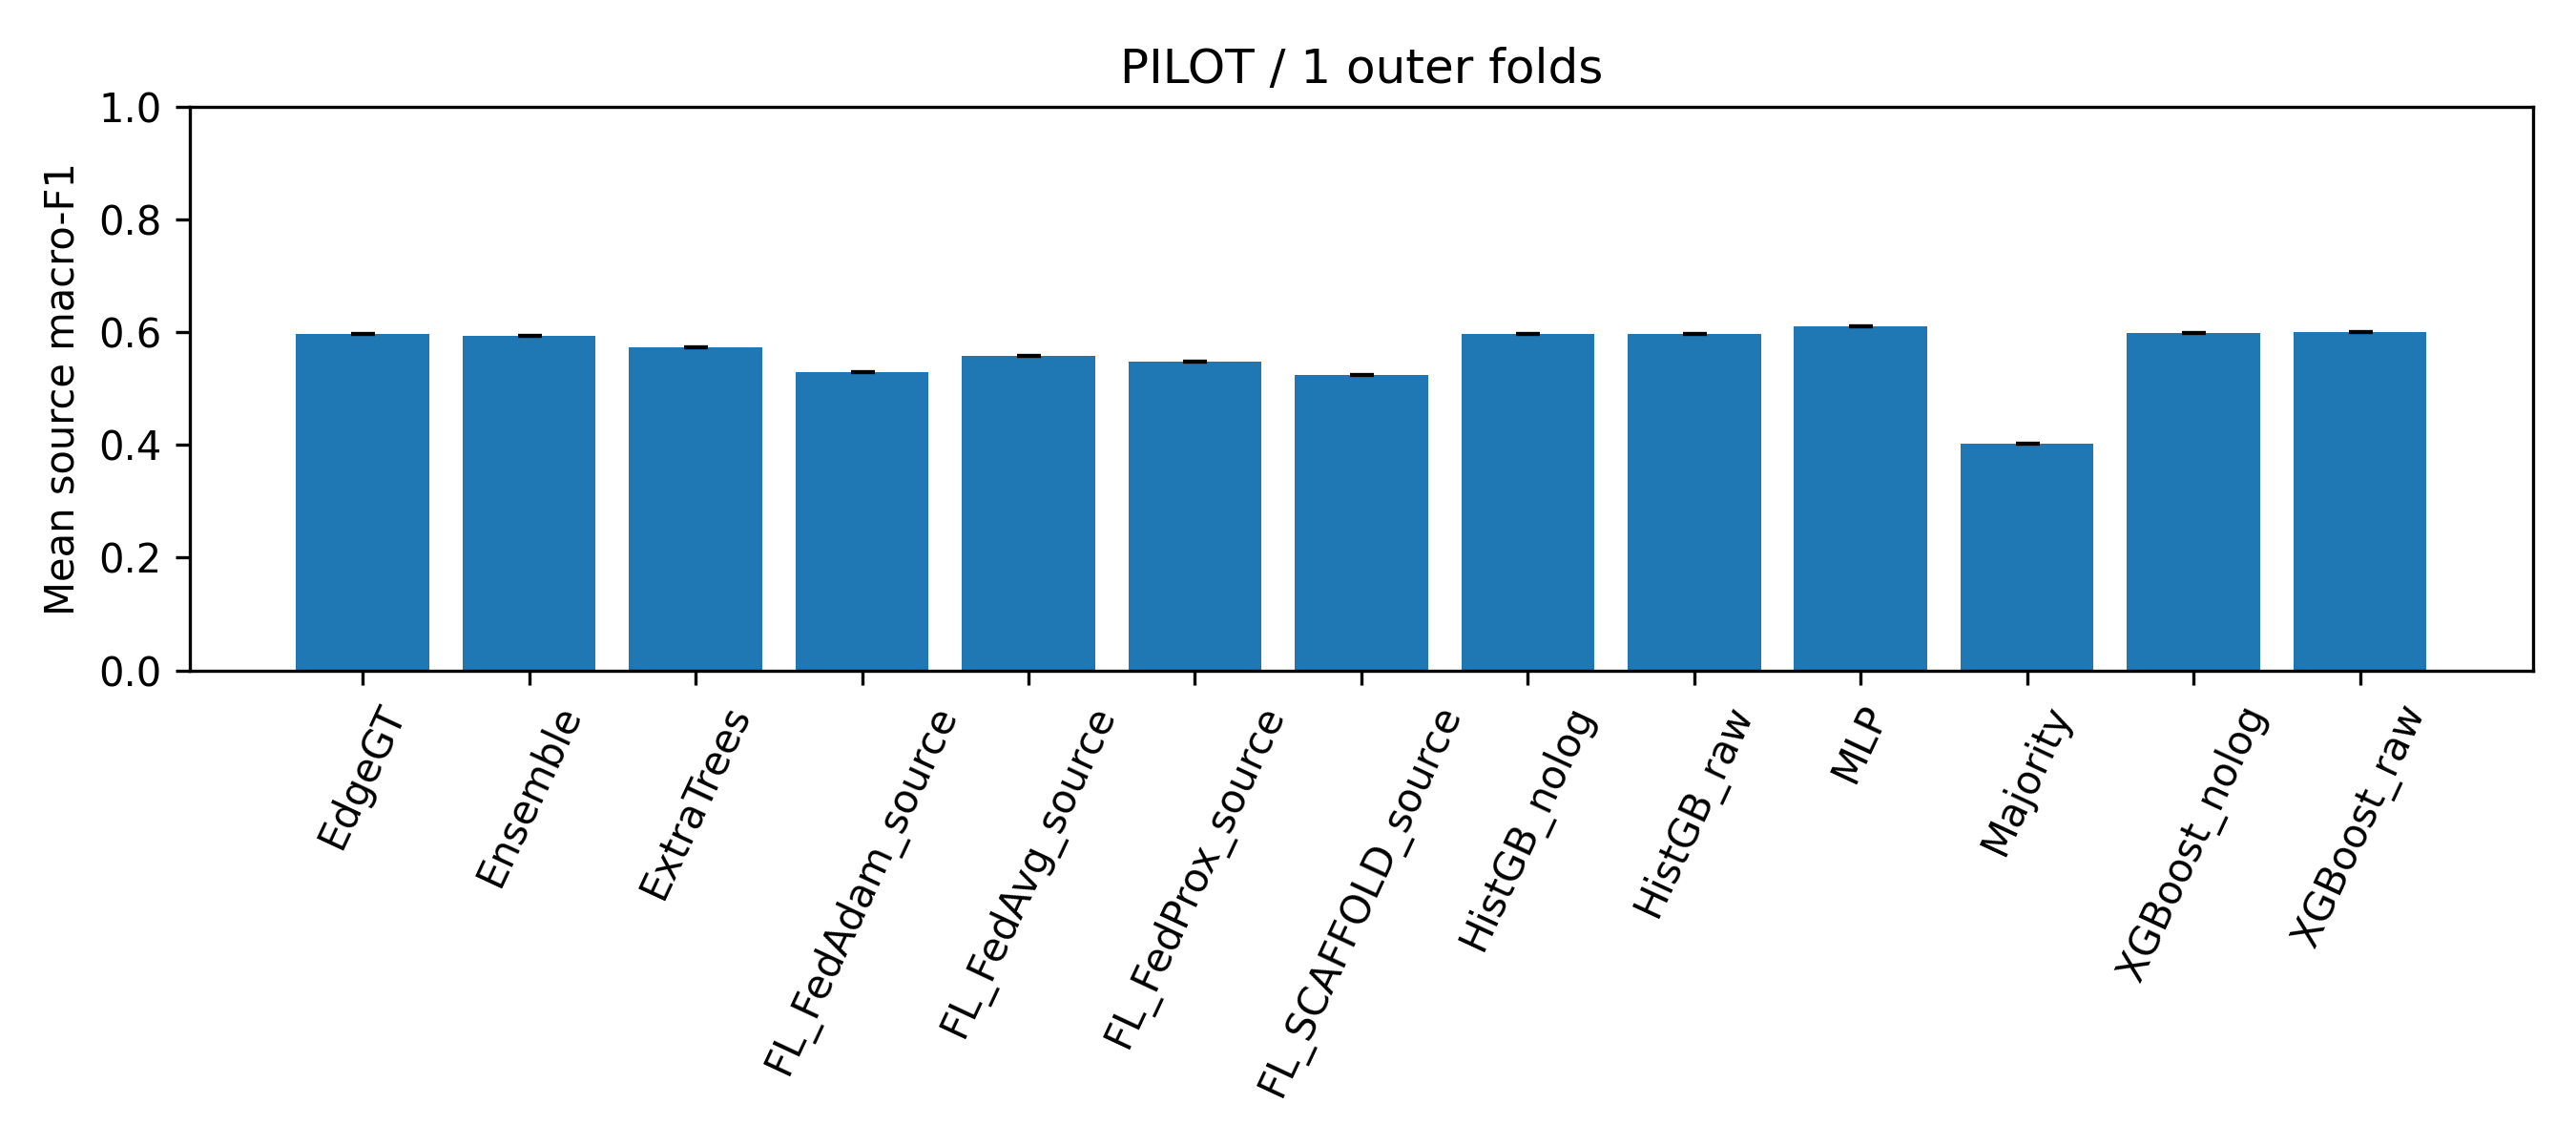

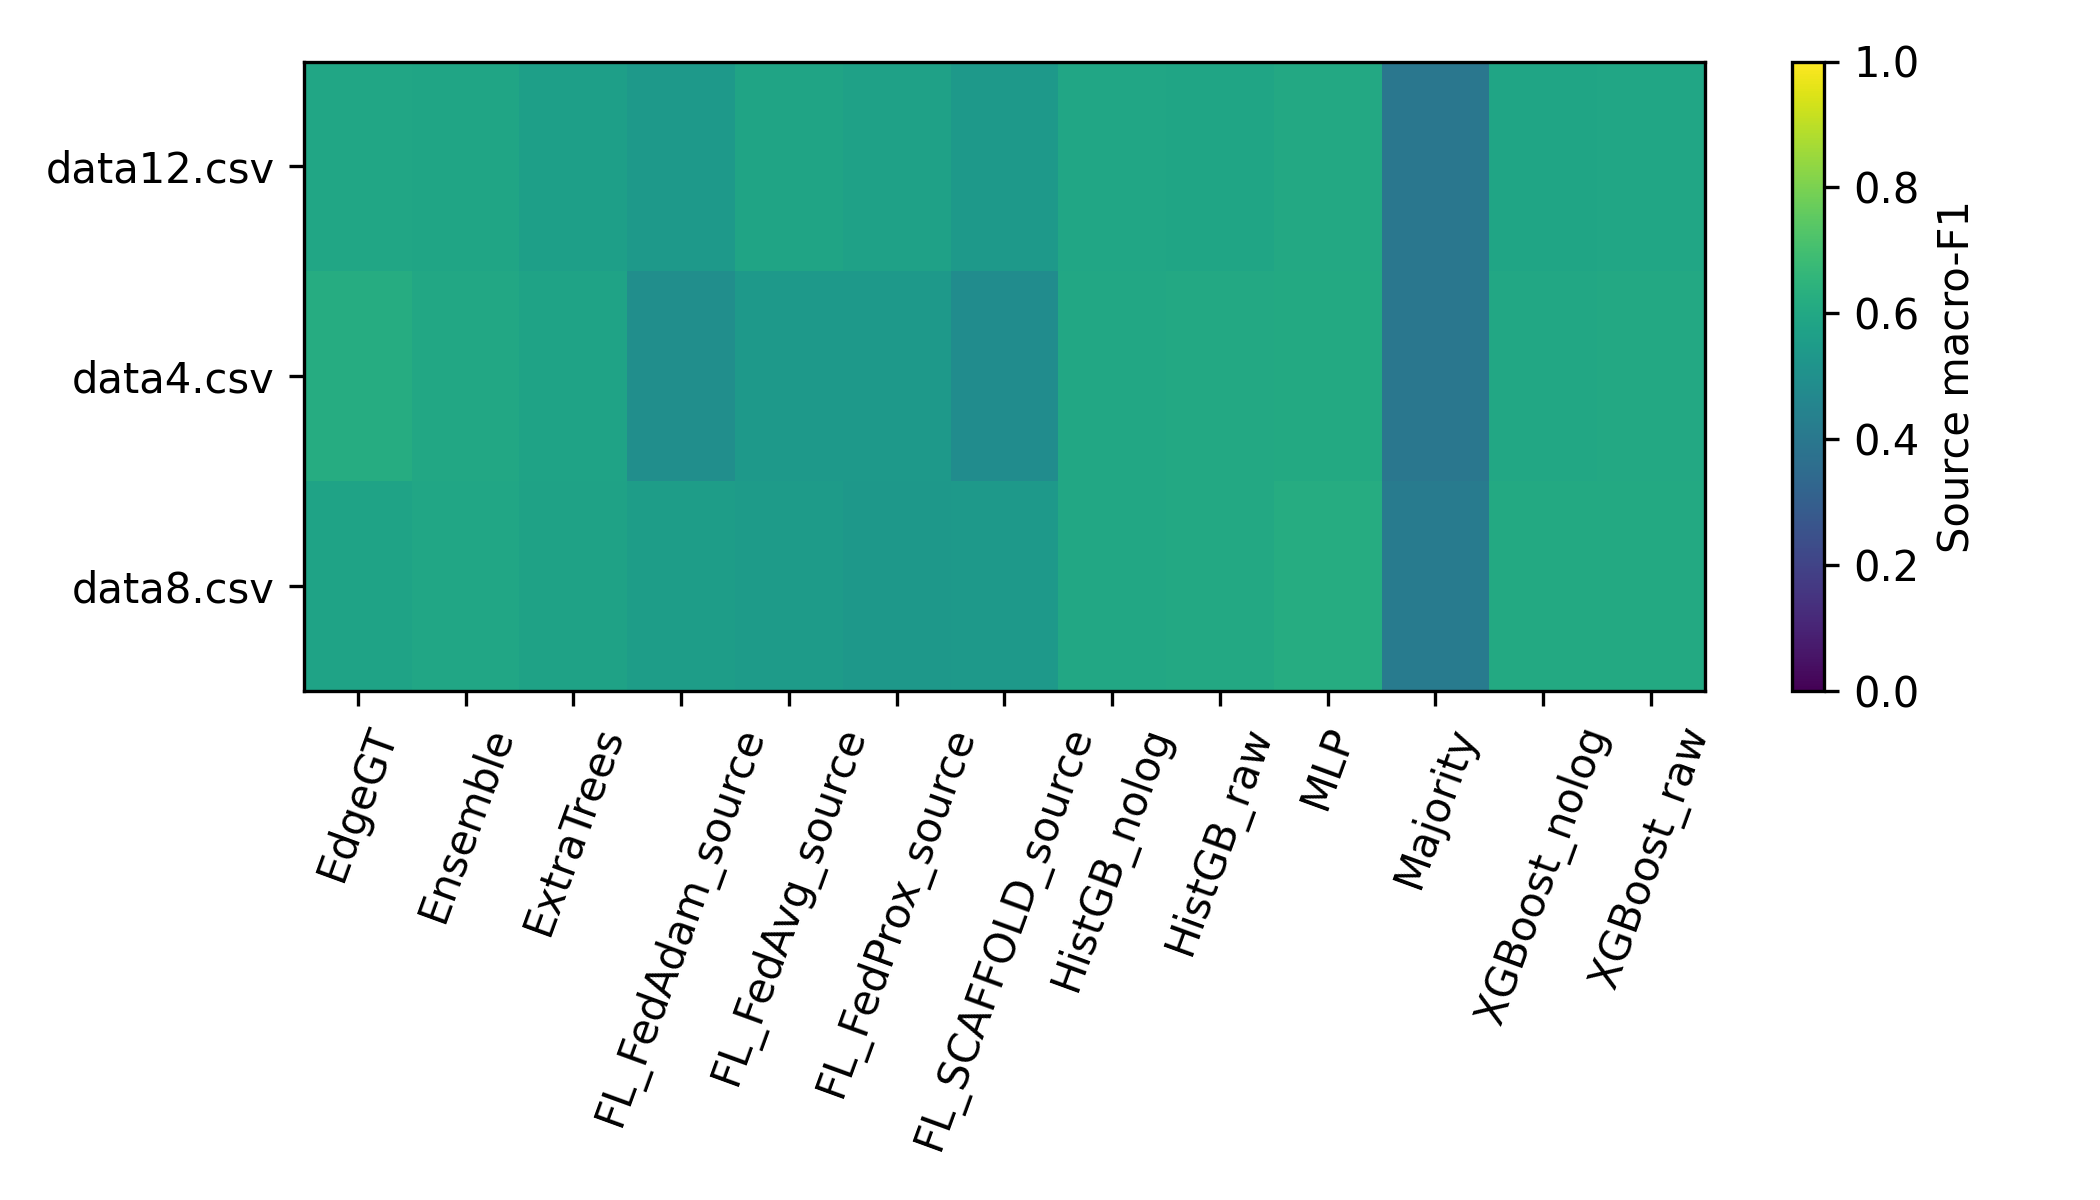

In [19]:
out = Path(cfg.output_dir)
metadata = json.loads((out / "run_metadata.json").read_text())
print("Status:", metadata["status"])
print("Completed folds:", metadata["completed_folds"])
print("Full protocol completed:", metadata["full_protocol_completed"])
display(pd.read_csv(out / "source_bootstrap_ci.csv"))
display(pd.read_csv(out / "per_source_metrics.csv").head(15))
from IPython.display import Image, display
if (out / "source_f1.png").exists():
    display(Image(filename=str(out / "source_f1.png")))
if (out / "per_source_heatmap.png").exists():
    display(Image(filename=str(out / "per_source_heatmap.png")))

## 7. Optional result archive
Archive your generated outputs after completion. Raw datasets are not copied into this archive. Model checkpoints can make it large; Drive output folders can be retained directly.

In [20]:
MAKE_RESULTS_ARCHIVE = False
if MAKE_RESULTS_ARCHIVE:
    import shutil
    archive = shutil.make_archive(str(out) + "_archive", "zip", root_dir=out)
    print(archive)
    if importlib.util.find_spec("google.colab") is not None:
        from google.colab import files
        files.download(archive)

## Interpretation before writing the paper

- Verify the strongest tuned tree baseline before claiming graph/physics superiority.
- Physics auxiliary reconstruction is a representation regularizer; it is not a power-flow or PDE penalty.
- Keep random-row reference results separate from source-holdout results.
- Complete all five outer folds and three seed repetitions before reporting final means and variability.
- FL retains local training rows during optimization in a centralized benchmark simulator; secure aggregation and differential privacy are not implemented.
- Genuine temporal modeling is deferred until timestamp/order/scenario semantics are established.
- Document the assumed line topology and sequence-channel semantics with authoritative provenance.

See the accompanying README for ablations, exact accounting limits, calibration details, statistical assumptions and checkpoint inference.